In [ ]:
!pip install opencv-python matplotlib numpy

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

print("OpenCV Version:", cv2.__version__)
print("All libraries imported successfully!")

OpenCV Version: 5.1.0
All libraries imported successfully!


In [2]:

# Sample image
image1 = cv2.imread(r"Exercise2_RAJENDRA_PRASAD_Images/Exercise2_Rajendra_Prasad_img1.jpg")

image2 = cv2.imread(r"Exercise2_RAJENDRA_PRASAD_Images/Exercise2_Rajendra_Prasad_img2.jpg")

# Load images
print(type(image1))
print(type(image2))

print("Image 1 dimensions:", image1.shape)
print("Image 2 dimensions:", image2.shape)

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
Image 1 dimensions: (1920, 1080, 3)
Image 2 dimensions: (1308, 736, 3)


In [3]:
# Resize both images to 600 x 400 pixels
width = 600
height = 400

image1_resized = cv2.resize(
    image1, (width, height)
)

image2_resized = cv2.resize(
    image2, (width, height)
)

print("Images resized successfully!")
print("New dimensions:", image1_resized.shape)
print("New dimensions:", image2_resized.shape)

Images resized successfully!
New dimensions: (400, 600, 3)
New dimensions: (400, 600, 3)


In [4]:
# Define blending weights
alpha = 0.5
beta = 0.5
gamma = 0

# Perform weighted image blending
blended_image = cv2.addWeighted(
    image1_resized,
    alpha,
    image2_resized,
    beta,
    gamma
)

print("Image blending completed successfully!")

print("New dimensions:", image1_resized.shape)
print("New dimensions:", image2_resized.shape)

Image blending completed successfully!
New dimensions: (400, 600, 3)
New dimensions: (400, 600, 3)


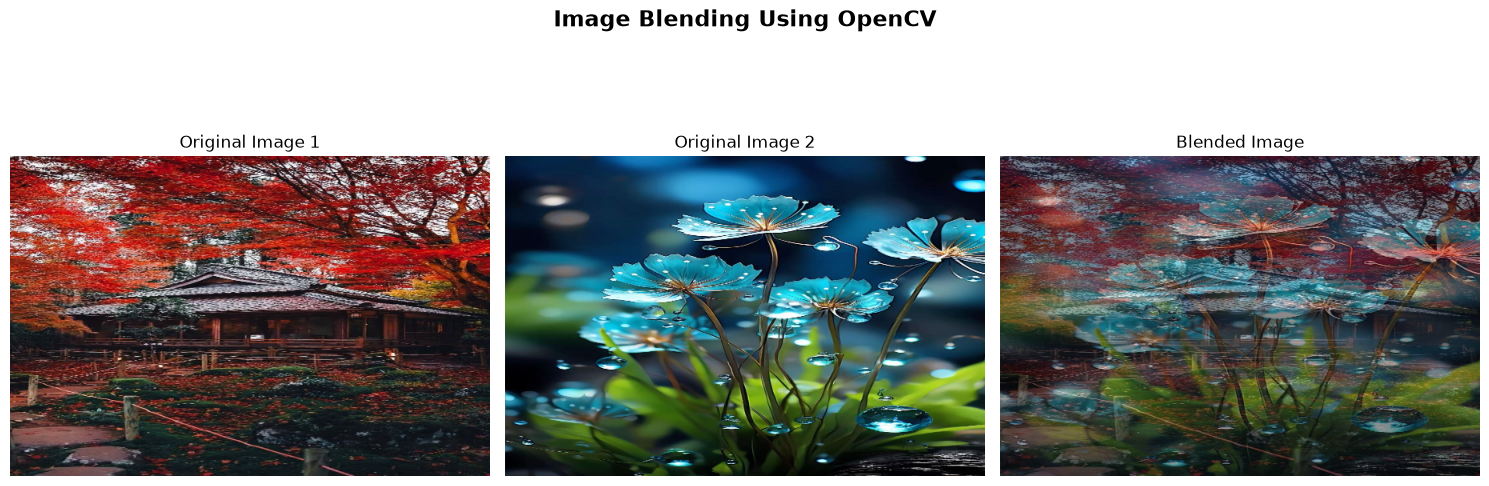

In [5]:
# Convert BGR to RGB
image1_rgb = cv2.cvtColor(
    image1_resized, cv2.COLOR_BGR2RGB
)

image2_rgb = cv2.cvtColor(
    image2_resized, cv2.COLOR_BGR2RGB
)

blended_rgb = cv2.cvtColor(
    blended_image, cv2.COLOR_BGR2RGB
)

# Display all three images
plt.figure(figsize=(15, 6))

plt.subplot(1, 3, 1)
plt.imshow(image1_rgb)
plt.title("Original Image 1")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(image2_rgb)
plt.title("Original Image 2")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(blended_rgb)
plt.title("Blended Image")
plt.axis("off")

plt.suptitle(
    "Image Blending Using OpenCV",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [6]:
# Save original resized images
cv2.imwrite(
    "Exercise2_RAJENDRA_PRASAD_Images/Original_Image1.jpg",
    image1_resized
)

cv2.imwrite(
    "Exercise2_RAJENDRA_PRASAD_Images/Original_Image2.jpg",
    image2_resized
)

# Save blended image
cv2.imwrite(
    "Exercise2_RAJENDRA_PRASAD_Images/Blended_Image.jpg",
    blended_image
)

print("All three images saved successfully!")

print("1. Exercise2_Rajendra_Prasad_Original_Image1.jpg")
print("2. Exercise2_Rajendra_Prasad_Original_Image2.jpg")
print("3. Exercise2_Rajendra_Prasad_Blended_Image.jpg")

All three images saved successfully!
1. Exercise2_Rajendra_Prasad_Original_Image1.jpg
2. Exercise2_Rajendra_Prasad_Original_Image2.jpg
3. Exercise2_Rajendra_Prasad_Blended_Image.jpg


In [7]:
# Verify that all output files exist
required_files = [
    "Exercise2_RAJENDRA_PRASAD_Images/Original_Image1.jpg",
    "Exercise2_RAJENDRA_PRASAD_Images/Original_Image2.jpg",
    "Exercise2_RAJENDRA_PRASAD_Images/Blended_Image.jpg"
]

for file in required_files:
    if os.path.exists(file):
        print("SUCCESS:", file)
    else:
        print("FAILED:", file)

print("\nExercise 2 completed successfully!")

SUCCESS: Exercise2_RAJENDRA_PRASAD_Images/Original_Image1.jpg
SUCCESS: Exercise2_RAJENDRA_PRASAD_Images/Original_Image2.jpg
SUCCESS: Exercise2_RAJENDRA_PRASAD_Images/Blended_Image.jpg

Exercise 2 completed successfully!


In [33]:
# Install ipywidgets if required
!pip install ipywidgets

Defaulting to user installation because normal site-packages is not writeable


In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import ipywidgets as widgets

from IPython.display import display, clear_output

# Create folder for storing images
os.makedirs("Exercise2_RAJENDRA_PRASAD_Images", exist_ok=True)

# Create upload widgets
upload_image1 = widgets.FileUpload(
    accept='image/*',
    multiple=False,
    description='Upload Image 1'
)

upload_image2 = widgets.FileUpload(
    accept='image/*',
    multiple=False,
    description='Upload Image 2'
)

# Display upload interface
display(widgets.HTML("<h3>Upload Two Images for Blending</h3>"))

display(upload_image1)
display(upload_image2)

HTML(value='<h3>Upload Two Images for Blending</h3>')

FileUpload(value=(), accept='image/*', description='Upload Image 1')

FileUpload(value=(), accept='image/*', description='Upload Image 2')

In [10]:
# Function to extract uploaded image data
def get_uploaded_file(upload_widget):

    if not upload_widget.value:
        raise ValueError("Please upload both images first!")

    # Handle ipywidgets versions
    uploaded = upload_widget.value

    if isinstance(uploaded, dict):
        file_info = list(uploaded.values())[0]
    else:
        file_info = uploaded[0]

    return file_info['content'], file_info['name']


# Get uploaded image data
image1_data, image1_name = get_uploaded_file(upload_image1)
image2_data, image2_name = get_uploaded_file(upload_image2)

# Convert uploaded bytes into OpenCV images
image1 = cv2.imdecode(
    np.frombuffer(image1_data, np.uint8),
    cv2.IMREAD_COLOR
)

image2 = cv2.imdecode(
    np.frombuffer(image2_data, np.uint8),
    cv2.IMREAD_COLOR
)

# Validate images
if image1 is None or image2 is None:
    raise ValueError("Invalid image format. Please upload valid images.")

# Save uploaded original images
folder = "Exercise2_RAJENDRA_PRASAD_Images"

cv2.imwrite(os.path.join(folder, "Original_Image1.jpg"), image1)
cv2.imwrite(os.path.join(folder, "Original_Image2.jpg"), image2)

print("Both images uploaded and loaded successfully!")

print("\nImage 1:", image1_name)
print("Image 2:", image2_name)

print("\nImage 1 dimensions:", image1.shape)
print("Image 2 dimensions:", image2.shape)

Both images uploaded and loaded successfully!

Image 1: Exercise2_Rajendra_Prasad_img1.jpg
Image 2: Exercise2_Rajendra_Prasad_img2.jpg

Image 1 dimensions: (1920, 1080, 3)
Image 2 dimensions: (1308, 736, 3)


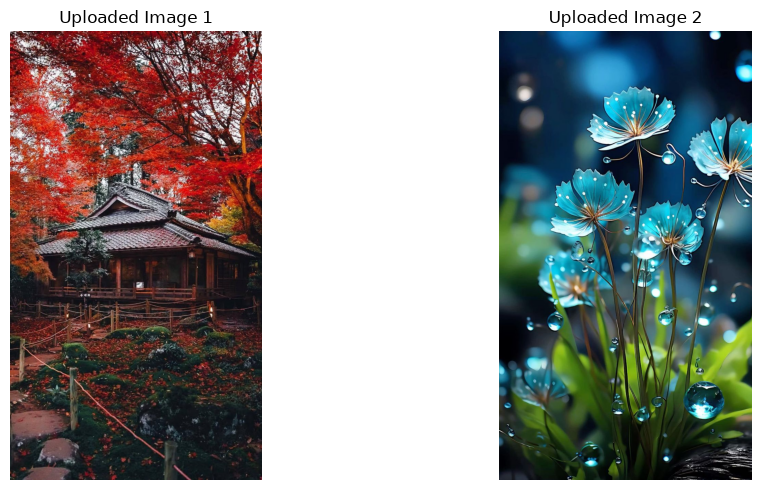

In [11]:
# Convert BGR to RGB
image1_rgb = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2_rgb = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image1_rgb)
plt.title("Uploaded Image 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image2_rgb)
plt.title("Uploaded Image 2")
plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# Resize images
width = 600
height = 400

image1_resized = cv2.resize(image1, (width, height))
image2_resized = cv2.resize(image2, (width, height))

# Blend images
blended_image = cv2.addWeighted(
    image1_resized, 0.6,
    image2_resized, 0.4,
    0
)

# Save blended output
cv2.imwrite(
    "Exercise2_RAJENDRA_PRASAD_Images/Blended_Image.jpg",
    blended_image
)

print("Image blending completed successfully!")

Image blending completed successfully!


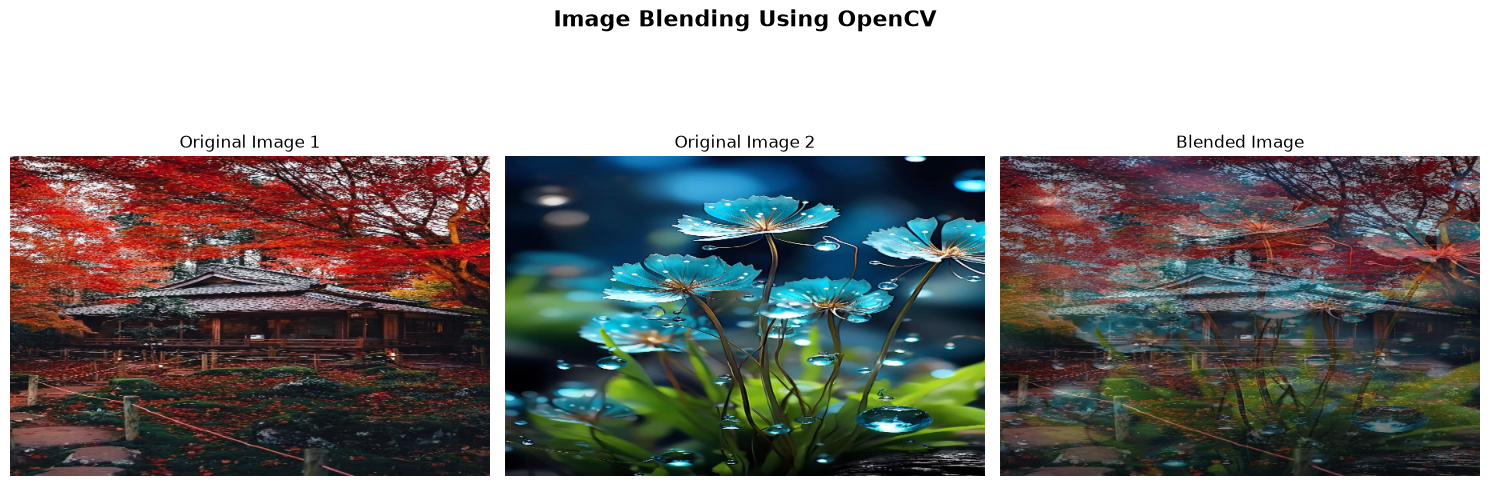

In [13]:
# Convert BGR to RGB
image1_rgb = cv2.cvtColor(
    image1_resized, cv2.COLOR_BGR2RGB
)

image2_rgb = cv2.cvtColor(
    image2_resized, cv2.COLOR_BGR2RGB
)

blended_rgb = cv2.cvtColor(
    blended_image, cv2.COLOR_BGR2RGB
)

# Display all three images
plt.figure(figsize=(15, 6))

plt.subplot(1, 3, 1)
plt.imshow(image1_rgb)
plt.title("Original Image 1")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(image2_rgb)
plt.title("Original Image 2")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(blended_rgb)
plt.title("Blended Image")
plt.axis("off")

plt.suptitle(
    "Image Blending Using OpenCV",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()